# Sección 2 · Diversidad genética

*Ho, He, Fis, incertidumbre y la relación con la latitud —* Nothofagus pumilio *(lenga)*

> **Cómo usar este notebook:** ejecuta las celdas en orden (Shift+Enter). Al final está la **Tarea**, que revisaremos al comienzo de la próxima sección.


In [1]:
# ---- Preparación (ejecutar primero) ----
# Tamaño de gráficos en Jupyter
options(repr.plot.width = 7, repr.plot.height = 4.5, repr.plot.res = 110)

source("R/helpers.R")
d <- load_clean(); G <- d$G; meta <- d$meta
meta$region <- assign_region(meta$lat)
pops <- aggregate(cbind(lat, lon, alt) ~ pop, data = meta, FUN = mean)

## Revisión de la tarea de la Sección 1

Antes de continuar, comparte tus 5 líneas de Métodos (los umbrales que elegiste y por qué).

- ¿Qué umbral te costó más justificar?
- Retomamos el **umbral de MAF** que en la Sección 1 quedó fijo sin justificar: en el ejercicio E3 verás cuánto cambia la diversidad estimada según ese umbral.
- Si hiciste la tabla de sensibilidad de la tarea, compártela: sirve para decidir los umbrales de tu *Métodos*.
- Retomemos la hipótesis: **¿esperas más diversidad genética al norte o al sur de la distribución de la lenga? ¿Por qué?** Anótala; la contrastaremos con el resultado al final de la sección.


## Objetivos de aprendizaje

1. Calcular **heterocigosidad observada (Ho)**, **esperada (He)** y **coeficiente de endogamia (Fis)** por población.
2. Cuantificar la **incertidumbre** (bootstrap sobre SNP) y comparar poblaciones y regiones.
3. Poner a prueba una hipótesis biogeográfica: **¿cambia la diversidad con la latitud?**
4. Entender cómo el **tamaño muestral** y el **filtro de MAF** sesgan la diversidad.


## 1. Conceptos: Ho, He y Fis

- **Ho (heterocigosidad observada):** proporción de individuos heterocigotos, promediada sobre SNP. *Ejemplo:* en un SNP, 3 de 10 individuos son heterocigotos → Ho = 0.3.
- **He (heterocigosidad esperada):** la que esperarías bajo equilibrio de Hardy-Weinberg. Para un SNP con frecuencia alélica *p*, He = 2p(1−p). *Ejemplo:* si p = 0.5 → He = 0.5.
- **Fis = 1 − Ho/He:** déficit (Fis > 0) o exceso (Fis < 0) de heterocigotos respecto a lo esperado. *Ejemplo:* Ho = 0.3 y He = 0.5 → Fis = 0.4 (déficit). Un Fis positivo sugiere endogamia o subestructura; negativo, mezcla reciente.

**Tres ideas que no debes soltar:**

1. **Ho, He y Fis cuentan historias distintas.** He refleja la *variación* de la población; Fis, *cómo se aparean* sus individuos.
2. **Tamaño muestral:** con pocos individuos He se subestima; usamos la corrección *2n/(2n−1)* (He insesgada de Nei).
3. **Independencia:** 20 poblaciones vecinas **no son** 20 observaciones independientes (comparten historia). Lo veremos al interpretar los p-valores.


## 2. Diversidad por población

`diversity_by_pop()` calcula Ho, He, Fis y la proporción de SNP polimórficos por población, ordenadas de norte a sur.

**¿Qué esperas?** Antes de mirar: ¿qué rango de He esperas (0–0.5)? ¿Fis positivo o negativo?


In [2]:
div <- diversity_by_pop(G, meta$pop)
div <- merge(div, pops, by = "pop")
div <- div[order(div$lat, decreasing = TRUE), ]   # de norte a sur
round_df <- function(x, k = 3) { x[sapply(x, is.numeric)] <- round(x[sapply(x, is.numeric)], k); x }
head(round_df(div), 8)

,pop,n_ind,Ho,He,Fis,prop_polim,lat,lon,alt
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,L01,12,0.324,0.337,0.037,0.928,-35.870,-71.334,1407
2,L02,10,0.324,0.332,0.027,0.906,-37.244,-71.474,1510
3,L03,12,0.323,0.331,0.027,0.915,-37.913,-71.738,1298
4,L04,12,0.320,0.328,0.023,0.920,-38.942,-71.433,1367
5,L05,12,0.316,0.323,0.022,0.914,-40.061,-71.780,1223
6,L06,12,0.318,0.326,0.024,0.906,-41.497,-71.673,1350
7,L07,12,0.316,0.325,0.028,0.903,-42.026,-71.763,1241
8,L08,12,0.328,0.334,0.017,0.905,-43.071,-72.140,1099


Primer vistazo a la relación con la latitud:


`geom_smooth()` using formula = 'y ~ x'


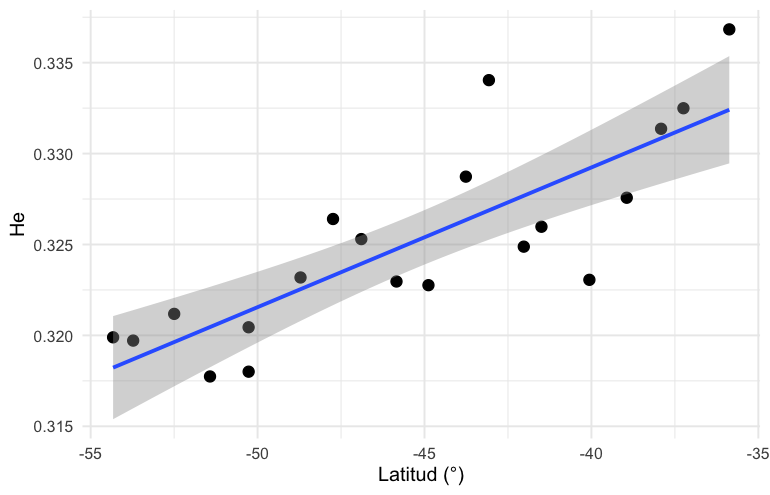

In [3]:
ggplot(div, aes(lat, He)) + geom_point(size = 3) + geom_smooth(method = "lm", se = TRUE) +
  labs(x = "Latitud (°)", y = "He") 

## 3. ¿Hay un gradiente latitudinal de diversidad?

Ajustamos una recta He ~ latitud y una correlación de Spearman. Recuerda el mensaje central: *una diferencia solo significa algo si sabes cuánto error y cuánto sesgo tiene.*

**Ojo con la interpretación:** n = 20 poblaciones, y las poblaciones vecinas **no son independientes**. Un p-valor pequeño aquí es evidencia *sugerente*, no definitiva.


In [4]:
m <- lm(He ~ lat, data = div)
summary(m)$coefficients
cor.test(div$lat, div$He, method = "spearman")

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),0.3599744298,0.0058365956,61.675410,2.119244e-22
lat,0.0007684415,0.0001277455,6.015408,1.092007e-05



	Spearman's rank correlation rho

data:  div$lat and div$He
S = 238, p-value = 5.696e-06
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.8210526 


## 4. Incertidumbre: bootstrap sobre SNP

Un **bootstrap** remuestrea los SNP con reemplazo y recalcula la estadística en cada réplica; el rango central de las réplicas es un intervalo de confianza aproximado.

Aquí comparamos dos poblaciones (L01 y L20). **¿Qué esperas?** Si los intervalos se solapan, la diferencia no es clara con estos datos.


In [5]:
set.seed(1)
boot_he <- function(Gk, B = 200) {
  replicate(B, {
    cols <- sample(ncol(Gk), replace = TRUE)
    diversity_by_pop(Gk[, cols], rep("x", nrow(Gk)))$He
  })
}
# ejemplo para una población (L01) y otra (L20)
b1  <- boot_he(G[meta$pop == "L01", ]); b20 <- boot_he(G[meta$pop == "L20", ])
rbind(L01 = quantile(b1, c(.025, .5, .975)), L20 = quantile(b20, c(.025, .5, .975)))

,2.5%,50%,97.5%
L01,0.3276741,0.3368079,0.3470901
L20,0.3107413,0.3200015,0.3286195


## 5. Comparación entre regiones

Agrupamos por región (Norte, Centro, Sur, definidas por latitud) y comparamos con un test de Kruskal-Wallis (no paramétrico, pensado para pocas poblaciones).

**¿Qué esperas?** ¿Qué región tendrá más dispersión? ¿Y si el esfuerzo de muestreo difiere entre regiones?


region,Ho,He,Fis
<fct>,<dbl>,<dbl>,<dbl>
Sur,0.3101717,0.3200240,0.03078334
Centro,0.3181490,0.3263815,0.02522860
Norte,0.3212697,0.3302633,0.02716325



	Kruskal-Wallis rank sum test

data:  He by region
Kruskal-Wallis chi-squared = 12.3, df = 2, p-value = 0.002134


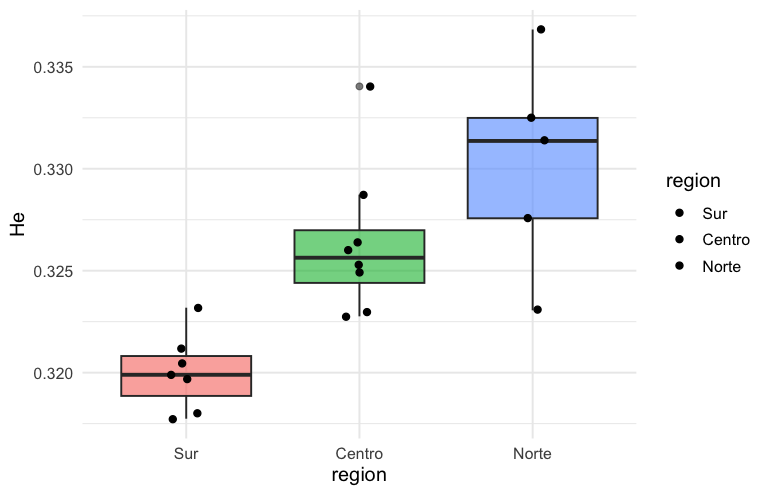

In [6]:
div$region <- assign_region(div$lat)
aggregate(cbind(Ho, He, Fis) ~ region, data = div, FUN = mean)
kruskal.test(He ~ region, data = div)
ggplot(div, aes(region, He, fill = region)) + geom_boxplot(alpha = .6, show.legend = FALSE) +
  geom_jitter(width = .1)

## 6. Diversidad individual

La heterocigosidad *multilocus* de cada individuo (proporción de SNP heterocigotos) permite ver la variación **dentro** de cada población.

**¿Qué esperas?** ¿Hay individuos atípicos? ¿Qué podrían indicar (migrante, error de etiquetado, contaminación)?


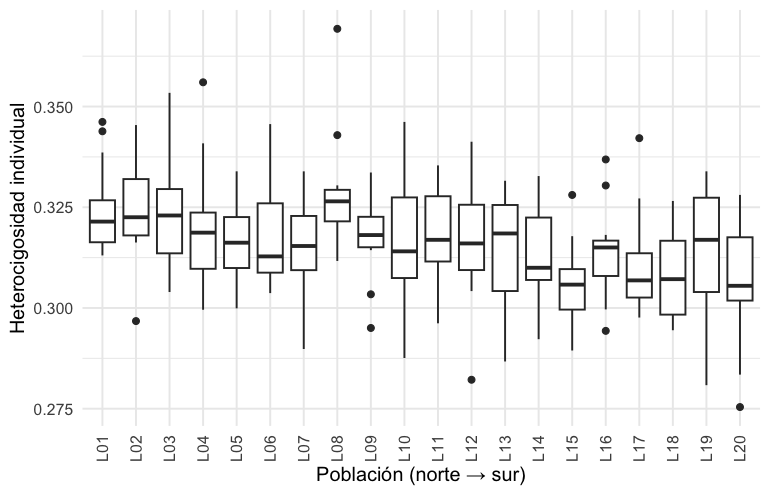

In [7]:
het_ind <- rowMeans(G == 1, na.rm = TRUE)       # heterocigosidad multilocus
ind_df  <- data.frame(meta, het = het_ind)
ggplot(ind_df, aes(reorder(pop, -lat), het)) + geom_boxplot() +
  labs(x = "Población (norte → sur)", y = "Heterocigosidad individual") +
  theme(axis.text.x = element_text(angle = 90, vjust = .5))

## 7. Alelos privados por región

Un **alelo privado** es una variante presente en una sola región y ausente en las demás: una señal de aislamiento o de historia independiente.

**Cuidado:** el número de alelos privados depende del **tamaño de muestra** (más individuos = más variantes raras detectadas). Compara regiones solo con tamaños equivalentes o usa rarefacción.


In [8]:
reg <- factor(meta$region)
Pr  <- t(sapply(levels(reg), function(r) colMeans(G[reg == r, ], na.rm = TRUE) / 2))
privados <- sapply(seq_len(nrow(Pr)), function(i) {
  otros <- Pr[-i, , drop = FALSE]
  sum(Pr[i, ] > 0 & colSums(otros > 0) == 0) +      # ALT presente solo aquí
  sum(Pr[i, ] < 1 & colSums(otros < 1) == 0)        # REF presente solo aquí
})
setNames(privados, levels(reg))
table(reg)     # ¡el esfuerzo de muestreo difiere!

Sur Centro  Norte 
     0      0      0

reg
   Sur Centro  Norte 
    82     94     58 

---

## Ejercicios

**E1.** Ajusta `lm(He ~ lat)`, `lm(Ho ~ lat)` y `lm(Fis ~ lat)`. ¿Cambian las conclusiones? Grafica los tres resultados.

> **Idea clave:** una métrica puede mostrar gradiente y otra no; reporta las tres.


In [9]:
# TU CÓDIGO AQUÍ

**E2. Sesgo por tamaño de muestra.** Submuestrea 4, 6, 8 y 12 individuos por población (20 réplicas cada uno), recalcula He y Fis y grafica media y dispersión vs. n. ¿A partir de qué n se estabiliza?

> **Idea clave:** con n pequeño la dispersión es alta; define el mínimo aceptable para tu estudio real.


In [10]:
# Pista: split(seq_len(nrow(G)), meta$pop) + sample()

**E3. Sesgo de verificación.** Recalcula la diversidad usando solo SNP con MAF > 0.05, > 0.10 y > 0.20. ¿Cómo cambia la relación He ~ latitud?

> **Idea clave:** subir el umbral de MAF sube He; compara poblaciones solo con el mismo filtro.


In [11]:
# TU CÓDIGO AQUÍ

**E4.** Reemplaza la regresión por una versión que considere la autocorrelación espacial (p. ej. `nlme::gls` con `corExp`, o una prueba de permutación que permute poblaciones dentro de regiones). Discute qué cambia.

> **Idea clave:** con dependencia espacial, los p-valores ingenuos son demasiado optimistas.


In [12]:
# TU CÓDIGO AQUÍ

## Errores y dudas frecuentes

- **«Mi bootstrap da intervalos muy anchos»** → es lo esperable con pocas poblaciones/individuos; no es un error.
- **«Fis me da negativo en alguna población»** → posible con n pequeño; no interpretes un valor aislado.
- **«¿Por qué la He insesgada?»** → porque la estimación simple subestima con muestras chicas.
- **«¿Puedo comparar mis resultados con la literatura?»** → solo si el tipo de marcador y el filtro son comparables.


## Resumen: ideas que debes llevarte

1. **Ho, He y Fis** miden cosas distintas: variación (He) y apareamiento (Fis).
2. Un resultado **sin incertidumbre ni sesgo conocido no es un resultado**.
3. El **bootstrap** cuantifica la incertidumbre; el **tamaño muestral** y el **filtro de MAF** son fuentes de sesgo.
4. La **independencia** de las poblaciones es una suposición que casi siempre se viola; desconfía de un p-valor ingenuo.

> *Contrasta tu hipótesis inicial:* ¿coincide lo observado con lo que esperabas (más diversidad al norte o al sur)?


## Tarea (se revisa al comienzo de la próxima sección)

1. Prepara un gráfico **«publicable»** de He por población, ordenado por latitud, con barras de error bootstrap.
2. Redacta en una frase tu conclusión **sin usar la palabra «significativo»**: describe magnitud e incertidumbre. Por ejemplo: *«observamos una tendencia a menor diversidad hacia el sur, con incertidumbre»*.

*Pregunta de reflexión:* si observaras menor diversidad al sur, ¿qué hipótesis alternativas podrían explicarlo (efectos fundadores post-glaciares, tamaño poblacional, refugios, error de muestreo, sesgo de verificación)? ¿Qué dato adicional las distinguiría?
